### The modes of `im_cc3m_2x4k_e20`

The KAE stands in for CLIP ViT-B/32's blocks 7 to 12. It encodes the state after block 6, applies K once, and decodes a prediction of the state after block 12. CLIP's own last layers and zero-shot classifier then read the predicted CLS token as if it were the real block 12.

A state is the CLS token, the mean of the 49 patch tokens and their spread (std), so 2,304 numbers per block. Only the CLS part goes through CLIP's head.

`im_cc3m_2x4k_e20`:
- Encoder and decoder are MLPs with two hidden layers of 4096. The latent has 2049 coordinates: one real eigenvalue and 1024 blocks `[[a, -b], [b, a]]`. Each block is one mode, with eigenvalues `a ± ib`.
- TopK keeps the 128 largest of the 1025 modes for each image and zeroes the rest. With shared modes, block 12 keeps the modes picked at block 6.
- Trained on 3 augmented views of ImageNet plus CC3M, with reconstruction, latent and state prediction, and two losses read through CLIP's last layers: the cosine between final embeddings (weight 1) and the KL between zero-shot class probabilities (weight 0.03). No isometric loss.
- Checkpoint from epoch 5 of a planned 20 (wandb `augtmhvc`), where the run was stopped. Without the isometric loss its latents are inflated on a few images; see the section on latent size.

Dampening a mode means scaling its eigenvalue: we multiply `a` and `b` of one block of K by `alpha`. Nothing else changes.

In [1]:
import copy
import os
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
from datasets import load_dataset
from dotenv import load_dotenv
from PIL import Image
from safetensors.torch import load_file
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

sys.path.insert(0, "../scripts/tokae")
from train import JordanKoopmanAutoencoder, compute_fvu, encode_pairs

load_dotenv("../.env")
torch.set_grad_enabled(False)
torch.manual_seed(0)
torch.set_num_threads(16)
pd.set_option("display.width", 200)

NAME = "im_cc3m_2x4k_e20"
CKPT_DIR = Path("/tmp/claude-1001/-home-dunstan-git-koopmann/0bba89b8-c8c4-41c4-a0d8-5b331c6750fd/scratchpad/ckpt_live")
# From wandb, for this checkpoint's epoch. The prediction cell must reproduce them, or loading is wrong.
EXPECTED = {"zero-shot accuracy": 0.5071, "agrees with CLIP": 0.6062}
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
NUM_RANDOM = 6
NUM_COHERENT = 6
SNOW_FOLDERS = {
    "armytank": 847,
    "carwheel": 479,
    "firetruck": 555,
    "motorscooter": 670,
    "racingcar": 751,
    "schoolbus": 779,
    "trafficlight": 920,
}

BLUE, ORANGE, MUTED, INK = "#2a78d6", "#eb6834", "#898781", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e8e7e3",
        "grid.linewidth": 0.6,
        "legend.frameon": False,
    }
)

/tmp/claude-1001/-home-dunstan-git-koopmann/0bba89b8-c8c4-41c4-a0d8-5b331c6750fd/scratchpad/venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


##### Model and data

States are standardized with the statistics the model was trained with. Activity is the size of a mode's coefficient at block 6, and TopK leaves most of them at exactly zero. With shared modes, block 12 keeps the modes picked at block 6, so block-6 activity says which modes an image uses.

In [2]:
head_dir = Path(os.getenv("WEIGHTS_CACHE")) / "tokae"
root = Path(os.getenv("DATASETS_CACHE"))
stats = torch.load(CKPT_DIR / f"{NAME}_stats.pt")
# NOTE: Global stats are one vector for both blocks; this also covers per-block stats
mean, std = stats["mean"].expand(2, -1), stats["std"].expand(2, -1)

# shape: [images, 2, 2304], the state after blocks 6 and 12
val = torch.load(root / "imagenet" / "clip_cls_patch_std_ViT-B-32_val_blocks_5_11.pt")
val_x, val_y = (val["states"] - mean) / std, val["labels"]
images = load_dataset("ILSVRC/imagenet-1k", split="validation", cache_dir=os.getenv("DATASETS_CACHE"))
assert torch.equal(val_y, torch.tensor(list(images["label"]))), "cached labels don't follow the image order"
class_names = open_clip.IMAGENET_CLASSNAMES

kae = JordanKoopmanAutoencoder(
    top_k=256,
    shared_modes=stats.get("shared_modes", False),
    in_features=val_x.shape[-1],
    latent_features=2049,
    hidden_config=stats.get("hidden_config", [2048]),
    bias=True,
    batchnorm=False,
    nonlinearity="leaky_relu",
)
kae.load_state_dict(load_file(CKPT_DIR / f"{NAME}.safetensors"))
kae.eval()

# shape: [modes]. Mode 0 is the real eigenvalue, mode m > 0 is the block on latent coordinates 2m - 1 and 2m
eigenvalues = torch.cat([kae.real_eigenvalue.to(torch.cfloat), torch.complex(kae.block_real, kae.block_imag)])


def predict(model, start):
    """The KAE's prediction of block 12 from block 6, both standardized."""

    return torch.cat([model.decode(model.koopman_forward(model.encode(batch), 1)) for batch in start.split(5_000)])


def get_activity(start):
    """How strongly each mode is on for each image, at block 6."""

    phi = torch.cat([kae.encode(batch) for batch in start.split(5_000)])
    return torch.cat([phi[:, :1].abs(), phi[:, 1:].unflatten(-1, (-1, 2)).norm(dim=-1)], dim=-1)


def dampen(mode, alpha):
    """A copy of the KAE whose K has one eigenvalue scaled by alpha."""

    edited = copy.deepcopy(kae)
    if mode == 0:
        edited.real_eigenvalue.mul_(alpha)
    else:
        edited.block_real[mode - 1].mul_(alpha)
        edited.block_imag[mode - 1].mul_(alpha)
    return edited


# shape: [images, modes]
activity = get_activity(val_x[:, 0])
usage = (activity > 0).double().mean(dim=0)
print(f"{NAME}: hidden {stats.get('hidden_config', [2048])}, shared modes {stats.get('shared_modes', False)}, standardization {stats.get('standardization', 'global')}")

/home/dunstan/git/koopmann/koopmann/models/autoencoder.py:48: UserWarning: The latent dimension 2049 should probably be larger than the input dimension 2304!
  warnings.warn(


im_cc3m_2x4k_e20: hidden [4096, 4096], shared modes True, standardization global


##### CLIP's last layers

`embed` turns the CLS part of a block 12 state into CLIP's final image embedding. The zero-shot classifier compares it with the text of ImageNet's 1000 classes, and the snow score is the embedding along "a photo in the snow" minus "a photo".

In [3]:
clip, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai",
    force_quick_gelu=True,  # OpenAI's weights were trained with QuickGELU
    cache_dir=f"{os.getenv('HF_HOME')}/open_clip",
)
clip.eval()
tokenizer = open_clip.get_tokenizer("ViT-B-32")
head = torch.load(head_dir / "zero_shot_head_ViT-B-32.pt")
width = clip.visual.ln_post.normalized_shape[0]


def embed(states):
    """CLIP's final embedding, from the CLS part of a standardized block 12 state."""

    cls = states[..., :width] * std[1, :width] + mean[1, :width]
    out = clip.visual.ln_post(cls) @ clip.visual.proj
    return out / out.norm(dim=-1, keepdim=True)


def classify(states):
    return (embed(states) @ head).argmax(dim=-1)


def embed_text(prompt):
    out = clip.encode_text(tokenizer([prompt]))[0]
    return out / out.norm()


snow_direction = embed_text("a photo in the snow") - embed_text("a photo")
snow_direction = snow_direction / snow_direction.norm()

##### Prediction

Zero-shot accuracy on ImageNet's 50,000 validation images, and how often the KAE gives the same answer as CLIP, right or wrong. These must match the numbers wandb logged for this checkpoint.

In [4]:
true_answers = classify(val_x[:, 1])
answers = classify(predict(kae, val_x[:, 0]))
scores = {
    "zero-shot accuracy": (answers == val_y).double().mean().item(),
    "agrees with CLIP": (answers == true_answers).double().mean().item(),
}
for key, value in scores.items():
    assert abs(value - EXPECTED[key]) < 0.002, f"{key}: {value:.4f} here, {EXPECTED[key]} on wandb"

pd.DataFrame(
    {
        "CLIP": {"zero-shot accuracy": (true_answers == val_y).double().mean().item(), "agrees with CLIP": 1.0},
        "KAE": scores,
    }
).T.round(3)

,zero-shot accuracy,agrees with CLIP
CLIP,0.633,1.000
KAE,0.507,0.606


##### How latent size is spread over images

The latent loss is a pooled FVU: the prediction error summed over a batch, divided by the latent variance summed over the batch. If a few images get enormous latents along easy modes, they dominate the denominator and the pooled FVU looks small while the typical image is predicted badly. Here: each image's latent energy (sum of squares) at both blocks, the share held by the top 1% of images, and each image's own relative error, `|λ·z₆ − z₁₂|² / |z₁₂|²`. Images in the top 1% at block 6 are flagged in the galleries below.

Pooled latent FVU 0.1409; per-image relative error: median 0.1953, 90th percentile 0.2607


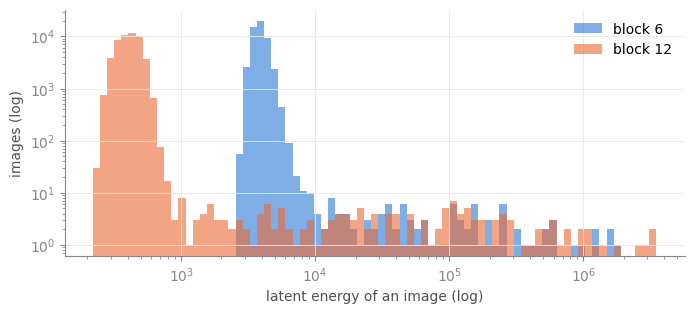

,median,99th percentile,max / median,top 1% share
block 6,3820.401,5453.878,465.418,0.107
block 12,411.360,615.479,8543.723,0.635


In [5]:
phi = torch.cat([encode_pairs(kae, batch) for batch in val_x.split(5_000)])
pred_phi = kae.koopman_forward(phi[:, 0], 1)
energy = phi.pow(2).sum(dim=-1)
relative_error = (pred_phi - phi[:, 1]).pow(2).sum(dim=-1) / energy[:, 1].clamp_min(1e-12)
outlier = energy[:, 0] >= energy[:, 0].quantile(0.99)

rows = {}
for block, column in [("block 6", 0), ("block 12", 1)]:
    e = energy[:, column]
    top = e.topk(len(e) // 100).values
    rows[block] = {
        "median": e.median().item(),
        "99th percentile": e.quantile(0.99).item(),
        "max / median": (e.max() / e.median()).item(),
        "top 1% share": (top.sum() / e.sum()).item(),
    }
print(f"Pooled latent FVU {compute_fvu(pred_phi[:, None], phi[:, 1:]).item():.4f}; per-image relative error: median {relative_error.median():.4f}, 90th percentile {relative_error.quantile(0.9):.4f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(np.log10(energy.min().item() + 1e-6), np.log10(energy.max().item()), 80)
for column, label, color in [(0, "block 6", BLUE), (1, "block 12", ORANGE)]:
    ax.hist(energy[:, column].numpy(), bins=bins, color=color, alpha=0.6, label=label)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("latent energy of an image (log)")
ax.set_ylabel("images (log)")
ax.legend()
plt.show()

pd.DataFrame(rows).T.round(3)

##### Finding the snow mode

129 photos of vehicles in snow ([Santurkar et al.](https://arxiv.org/abs/2112.01008)), against the 350 normal validation images of the same 7 classes. We score each mode by how well its activity alone separates snowy from normal images (AUC). CLIP gets the snowy images right far less often than the normal ones.

The snowy photos go through CLIP here, so first a check that this extraction (CLS, patch mean, patch std) matches the cached validation states on a few images.

In [6]:
def get_states(pixels):
    """Unstandardized states after blocks 6 and 12, built the way the training cache was."""

    states = []

    def keep(_, __, output):
        patches = output[:, 1:]
        states.append(torch.cat([output[:, 0], patches.mean(dim=1), patches.std(dim=1)], dim=-1))

    hooks = [clip.visual.transformer.resblocks[block].register_forward_hook(keep) for block in stats["blocks"]]
    clip.encode_image(pixels)
    for hook in hooks:
        hook.remove()
    return torch.stack(states, dim=1)


check = get_states(torch.stack([preprocess(images[i]["image"].convert("RGB")) for i in range(5)]))
cached = val["states"][:5].float()
gap = ((check - cached).norm(dim=-1) / cached.norm(dim=-1)).max().item()
print(f"Largest relative gap to the cached states: {gap:.2e}")
assert gap < 1e-2, "snowy states would not be comparable to the cached ones"

paths = sorted((root / "snowy_imagenet").glob("*/*.jpg"))
snowy_x = (get_states(torch.stack([preprocess(Image.open(path).convert("RGB")) for path in paths])) - mean) / std
snowy_y = torch.tensor([SNOW_FOLDERS[path.parent.name] for path in paths])

normal = torch.isin(val_y, torch.tensor(list(SNOW_FOLDERS.values())))
x, y = torch.cat([val_x[normal], snowy_x]), torch.cat([val_y[normal], snowy_y])
is_snowy = torch.cat([torch.zeros(int(normal.sum()), dtype=torch.bool), torch.ones(len(snowy_x), dtype=torch.bool)])


def get_aucs(act, labels):
    return torch.tensor([roc_auc_score(labels.numpy(), act[:, m].numpy()) if act[:, m].any() else 0.5 for m in range(act.shape[1])])


snow_activity = get_activity(x[:, 0])
aucs = get_aucs(snow_activity, is_snowy)
SNOW_MODE = int(aucs.argmax())

# Pick on one half of the snow test, score on the other, so the AUC isn't measured where the mode was picked
fold = torch.arange(len(y)) % 2
for half in [0, 1]:
    pick, test = fold == half, fold != half
    best = int(get_aucs(snow_activity[pick], is_snowy[pick]).argmax())
    held_out = roc_auc_score(is_snowy[test].numpy(), snow_activity[test, best].numpy())
    print(f"Half {half}: picks mode {best}, AUC on the other half {held_out:.3f}")

true_correct = classify(x[:, 1]) == y
print(f"Snow mode {SNOW_MODE}, |eigenvalue| {eigenvalues[SNOW_MODE].abs():.3f}, on for {usage[SNOW_MODE]:.1%} of validation")
print(f"CLIP: snowy {true_correct[is_snowy].double().mean():.3f}, normal {true_correct[~is_snowy].double().mean():.3f}")
pd.DataFrame(
    {
        "AUC": aucs.numpy(),
        "on for snowy": (snow_activity[is_snowy] > 0).double().mean(dim=0).numpy(),
        "on for normal": (snow_activity[~is_snowy] > 0).double().mean(dim=0).numpy(),
    }
).sort_values("AUC", ascending=False).head(5).round(3)

Largest relative gap to the cached states: 2.81e-06


Half 0: picks mode 471, AUC on the other half 0.943


Half 1: picks mode 471, AUC on the other half 0.974
Snow mode 471, |eigenvalue| 0.463, on for 11.3% of validation
CLIP: snowy 0.535, normal 0.643


,AUC,on for snowy,on for normal
471,0.959,0.992,0.431
837,0.886,1.000,0.894
102,0.845,1.000,1.000
854,0.822,0.752,0.174
89,0.753,1.000,1.000


##### The spectrum

One eigenvalue per mode. Each block also has the conjugate `a - ib`, so we plot the upper half only. Dot size is how often TopK keeps the mode. With one step from block 6 to block 12, an eigenvalue is a gain and a rotation applied once. The snow mode is orange.

1019 of 1025 modes are ever kept, 0 with |eigenvalue| >= 2 are off the plot


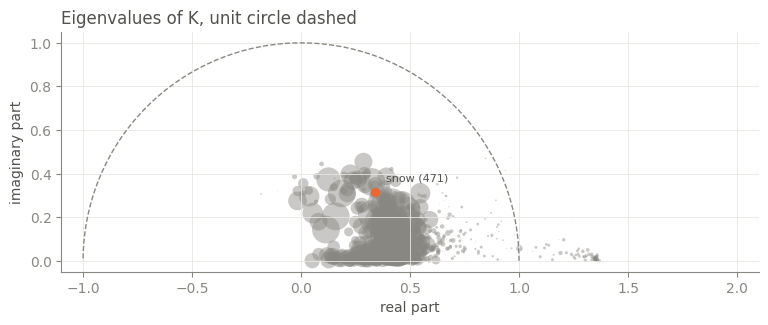

In [7]:
keep = eigenvalues.abs() < 2
print(f"{int((usage > 0).sum())} of {len(eigenvalues)} modes are ever kept, {int((~keep).sum())} with |eigenvalue| >= 2 are off the plot")

fig, ax = plt.subplots(figsize=(9, 3.6))
circle = np.exp(1j * np.linspace(0, np.pi, 200))
ax.plot(circle.real, circle.imag, color=MUTED, lw=1, ls="--")
ax.scatter(eigenvalues.real[keep].numpy(), eigenvalues.imag[keep].abs().numpy(), s=400 * usage[keep].numpy(), color=MUTED, alpha=0.45, lw=0)
snow = eigenvalues[SNOW_MODE]
ax.scatter(snow.real.item(), abs(snow.imag.item()), s=max(400 * usage[SNOW_MODE].item(), 12), color=ORANGE, lw=0, zorder=3)
ax.annotate(f"snow ({SNOW_MODE})", (snow.real.item(), abs(snow.imag.item())), xytext=(8, 8), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlim(-1.1, 2.1)
ax.set_xlabel("real part")
ax.set_ylabel("imaginary part")
ax.set_aspect("equal")
ax.set_title("Eigenvalues of K, unit circle dashed", loc="left", color=INK)
plt.show()

##### How many modes are coherent?

A rough check over every mode kept on at least 1% of images. We take each mode's top 16 validation images and measure how alike they are in CLIP's final embedding space: the mean cosine between pairs. A mode passes if it beats 99% of random sets of 16 images.

This is a low bar: 16 images of one class score far higher. So passing means "more alike than chance", not "interpretable".

Random sets of 16: 99th percentile 0.547. Sets of 16 from one class: median 0.709
81% of 808 modes beat random; 6 modes are never kept


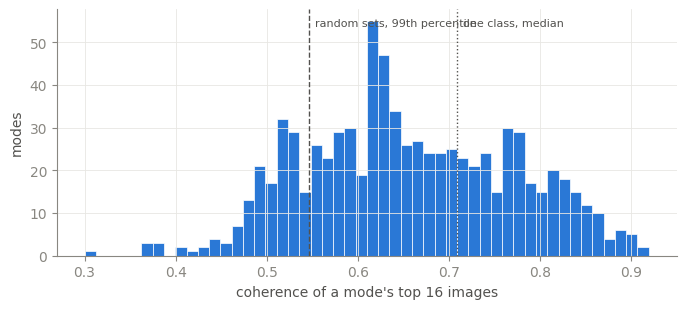

,modes,beat_random
kind,,
1-3 classes,162,0.981
4-8 classes,271,0.945
9-16 classes,375,0.643


In [8]:
candidates = (usage >= 0.01).nonzero()[:, 0]
true_embeddings = embed(val_x[:, 1])


def get_coherence(indices):
    """Mean cosine between the CLIP embeddings of a set of images, leaving out each image with itself."""

    similarity = true_embeddings[indices] @ true_embeddings[indices].T
    n = len(indices)
    return ((similarity.sum() - n) / (n * (n - 1))).item()


random_sets = np.array([get_coherence(torch.randperm(len(val_y))[:16]) for _ in range(1_000)])
class_sets = np.array([get_coherence((val_y == c).nonzero()[:, 0][:16]) for c in range(1_000)])
threshold = np.quantile(random_sets, 0.99)

rows = []
for mode in candidates.tolist():
    top = activity[:, mode].topk(16).indices
    rows.append(
        {
            "mode": mode,
            "coherence": get_coherence(top),
            "classes in top 16": len(set(val_y[top].tolist())),
            "latent outliers in top 16": int(outlier[top].sum()),
        }
    )
coherence = pd.DataFrame(rows).set_index("mode")
coherence["kind"] = pd.cut(coherence["classes in top 16"], [0, 3, 8, 16], labels=["1-3 classes", "4-8 classes", "9-16 classes"])

print(f"Random sets of 16: 99th percentile {threshold:.3f}. Sets of 16 from one class: median {np.median(class_sets):.3f}")
print(f"{(coherence['coherence'] > threshold).mean():.0%} of {len(coherence)} modes beat random; {int((usage == 0).sum())} modes are never kept")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(coherence["coherence"], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
for value, label, style in [(threshold, "random sets, 99th percentile", "--"), (np.median(class_sets), "one class, median", ":")]:
    ax.axvline(value, color=INK, lw=1, ls=style)
    ax.annotate(label, (value, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("coherence of a mode's top 16 images")
ax.set_ylabel("modes")
plt.show()

coherence.groupby("kind", observed=True)["coherence"].agg(modes="size", beat_random=lambda c: (c > threshold).mean()).round(3)

##### What some modes fire on

The 8 validation images where each mode is most active, with their ImageNet class underneath. First the snow mode, then the most coherent modes whose top 16 span at least 9 classes, picked automatically. A ★ marks an image in the top 1% of latent energy at block 6.

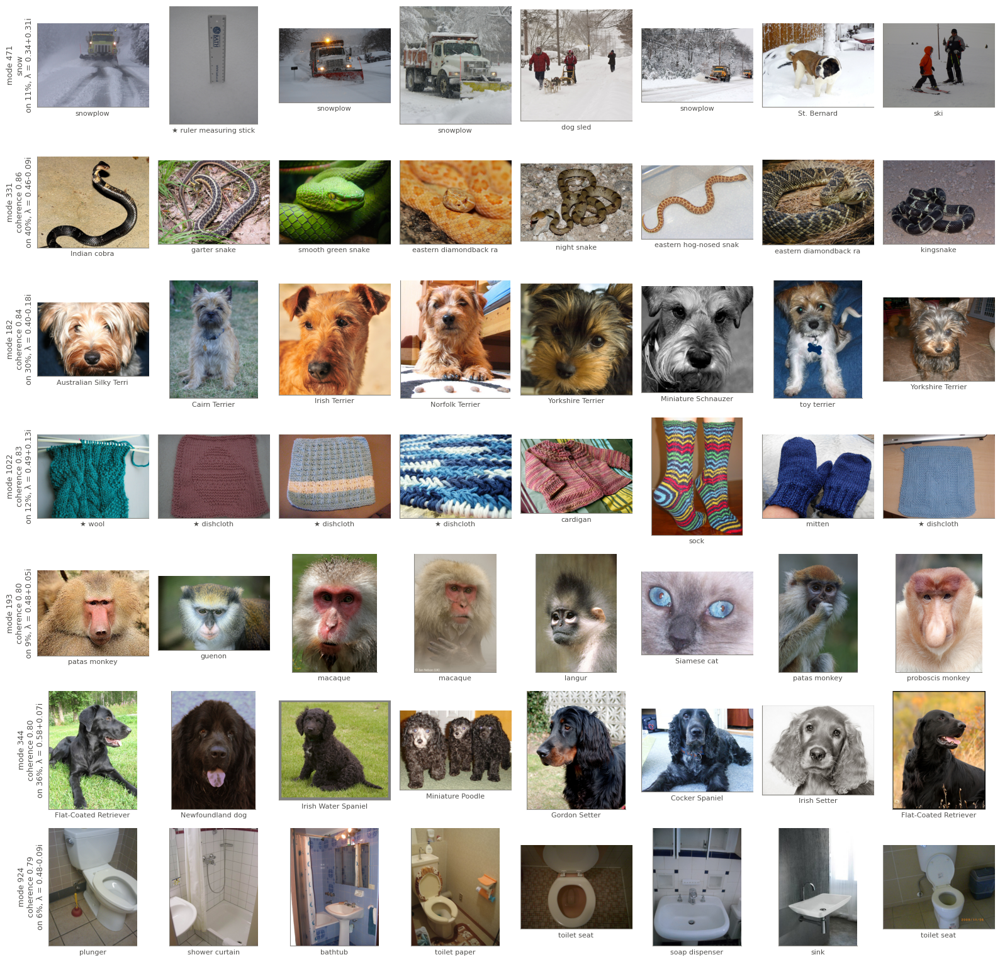

In [9]:
def show_modes(modes, labels):
    fig, axes = plt.subplots(len(modes), 8, figsize=(16, 2.2 * len(modes)), squeeze=False)
    for row, mode, label in zip(axes, modes, labels):
        for ax, index in zip(row, activity[:, mode].topk(8).indices.tolist()):
            image = images[index]["image"].convert("RGB")
            image.thumbnail((256, 256))
            ax.imshow(np.asarray(image))
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            star = "★ " if outlier[index] else ""
            ax.set_xlabel(f"{star}{class_names[val_y[index]][:22]}", fontsize=8, color=INK)
        real, imag = eigenvalues[mode].real.item(), eigenvalues[mode].imag.item()
        row[0].set_ylabel(
            f"mode {mode}\n{label}\non {usage[mode].item():.0%}, λ = {real:.2f}{imag:+.2f}i",
            fontsize=9,
            color=INK,
        )
    fig.tight_layout()
    plt.show()


cross_class = coherence[coherence["classes in top 16"] >= 9].sort_values("coherence", ascending=False)
picked = [m for m in cross_class.index[: NUM_COHERENT + 1].tolist() if m != SNOW_MODE][:NUM_COHERENT]
show_modes([SNOW_MODE, *picked], ["snow", *[f"coherence {cross_class.loc[m, 'coherence']:.2f}" for m in picked]])

Modes drawn at random from those kept on at least 1% of images, so that the gallery above isn't only the best picks.

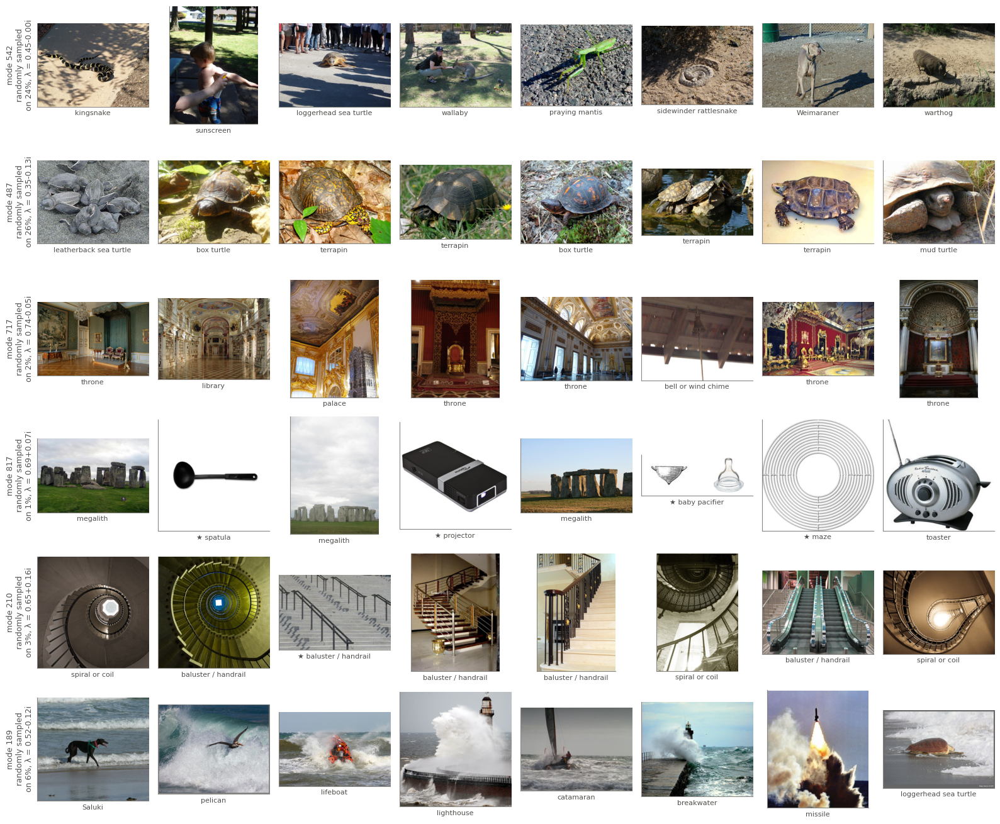

In [10]:
sample = candidates[torch.randperm(len(candidates))[:NUM_RANDOM]].tolist()
show_modes(sample, ["randomly sampled"] * NUM_RANDOM)

##### Dampening the snow eigenvalue

We scale the snow mode's eigenvalue by `alpha` and read the prediction with CLIP's zero-shot classifier. `alpha = 1` is K as trained, `alpha = 0` removes the mode, and `alpha > 1` excites it. The dotted lines are real CLIP.

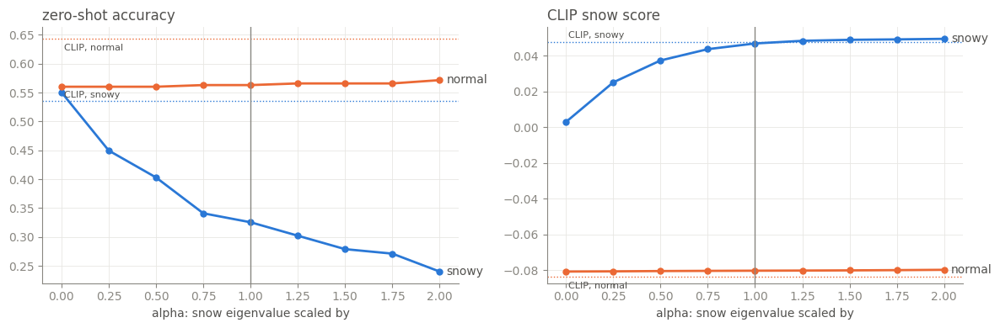

,"accuracy, snowy","accuracy, normal","snow score, snowy","snow score, normal"
alpha,,,,
0.00,0.550,0.560,0.003,-0.081
0.25,0.450,0.560,0.025,-0.081
0.50,0.403,0.560,0.037,-0.080
0.75,0.341,0.563,0.044,-0.080
1.00,0.326,0.563,0.047,-0.080
1.25,0.302,0.566,0.048,-0.080
1.50,0.279,0.566,0.049,-0.080
1.75,0.271,0.566,0.049,-0.080
2.00,0.240,0.571,0.050,-0.080


In [11]:
true_snow = embed(x[:, 1]) @ snow_direction
rows = []
for alpha in ALPHAS:
    prediction = predict(dampen(SNOW_MODE, alpha), x[:, 0])
    correct = classify(prediction) == y
    snow = embed(prediction) @ snow_direction
    rows.append(
        {
            "alpha": alpha,
            "accuracy, snowy": correct[is_snowy].double().mean().item(),
            "accuracy, normal": correct[~is_snowy].double().mean().item(),
            "snow score, snowy": snow[is_snowy].mean().item(),
            "snow score, normal": snow[~is_snowy].mean().item(),
        }
    )
sweep = pd.DataFrame(rows).set_index("alpha")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
panels = [
    ("accuracy", "zero-shot accuracy", true_correct.double()),
    ("snow score", "CLIP snow score", true_snow),
]
for ax, (key, title, truth) in zip(axes, panels):
    for group, color, mask in [("snowy", BLUE, is_snowy), ("normal", ORANGE, ~is_snowy)]:
        values = sweep[f"{key}, {group}"]
        ax.plot(values.index, values, color=color, lw=2, marker="o", ms=5)
        ax.annotate(group, (values.index[-1], values.iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK, va="center")
        ax.axhline(truth[mask].mean().item(), color=color, lw=1, ls=":")
        offset = (2, 3) if group == "snowy" else (2, -10)
        ax.annotate(f"CLIP, {group}", (ALPHAS[0], truth[mask].mean().item()), xytext=offset, textcoords="offset points", fontsize=8, color=INK)
    ax.axvline(1.0, color=MUTED, lw=1)
    ax.set_xlabel("alpha: snow eigenvalue scaled by")
    ax.set_title(title, loc="left", color=INK)
fig.tight_layout()
plt.show()

sweep.round(3)

##### How much damping is enough?

Counted per image: an image is fixed if its answer goes from wrong to right, and broken if it goes from right to wrong. On the left, the 479 snow-test images. On the right, every validation image where TopK keeps the snow mode. Images where TopK drops the mode never change.

The snow mode is kept for 5635 of 50000 validation images


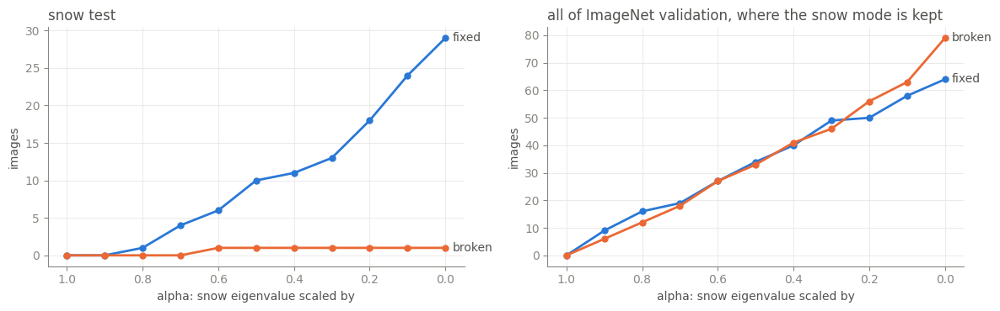

,snowy: fixed,snowy: broken,normal: fixed,normal: broken,ImageNet: fixed,ImageNet: broken
alpha,,,,,,
1.0,0,0,0,0,0,0
0.9,0,0,0,0,9,6
0.8,1,0,0,0,16,12
0.7,4,0,0,0,19,18
0.6,6,0,0,1,27,27
0.5,10,0,0,1,34,33
0.4,11,0,0,1,40,41
0.3,13,0,0,1,49,46
0.2,18,0,0,1,50,56


In [12]:
on = activity[:, SNOW_MODE] > 0
groups = {
    "snowy": (x[is_snowy, 0], y[is_snowy]),
    "normal": (x[~is_snowy, 0], y[~is_snowy]),
    "ImageNet": (val_x[on, 0], val_y[on]),
}
right = {group: classify(predict(kae, start)) == truth for group, (start, truth) in groups.items()}
print(f"The snow mode is kept for {int(on.sum())} of {len(val_y)} validation images")

rows = []
for alpha in np.linspace(1, 0, 11).round(1):
    edited = dampen(SNOW_MODE, alpha)
    row = {"alpha": alpha}
    for group, (start, truth) in groups.items():
        now = classify(predict(edited, start)) == truth
        row[f"{group}: fixed"] = int((~right[group] & now).sum())
        row[f"{group}: broken"] = int((right[group] & ~now).sum())
    rows.append(row)
damping = pd.DataFrame(rows).set_index("alpha")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
panels = [
    ("snow test", damping["snowy: fixed"] + damping["normal: fixed"], damping["snowy: broken"] + damping["normal: broken"]),
    ("all of ImageNet validation, where the snow mode is kept", damping["ImageNet: fixed"], damping["ImageNet: broken"]),
]
for ax, (title, fixed, broken) in zip(axes, panels):
    for values, label, color in [(fixed, "fixed", BLUE), (broken, "broken", ORANGE)]:
        ax.plot(values.index, values, color=color, lw=2, marker="o", ms=5)
        ax.annotate(label, (values.index[-1], values.iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK, va="center")
    ax.invert_xaxis()
    ax.set_xlabel("alpha: snow eigenvalue scaled by")
    ax.set_ylabel("images")
    ax.set_title(title, loc="left", color=INK)
fig.tight_layout()
plt.show()

damping

##### Which snowy images it fixes

Removing the mode (`alpha = 0`), the snowy images whose zero-shot answer goes from wrong to right.

Snowy images: 29 fixed, 0 broken, of 129
Normal images whose answer changes: 6 of 350


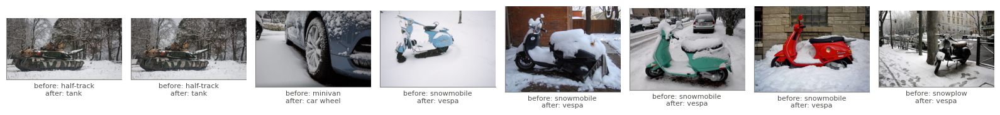

In [13]:
before_answers = classify(predict(kae, x[:, 0]))
removed = dampen(SNOW_MODE, 0.0)
after_answers = classify(predict(removed, x[:, 0]))

fixed = (is_snowy & (before_answers != y) & (after_answers == y)).nonzero()[:, 0]
broken = is_snowy & (before_answers == y) & (after_answers != y)
changed = ~is_snowy & (before_answers != after_answers)
print(f"Snowy images: {len(fixed)} fixed, {int(broken.sum())} broken, of {int(is_snowy.sum())}")
print(f"Normal images whose answer changes: {int(changed.sum())} of {int((~is_snowy).sum())}")

first_snowy = int((~is_snowy).sum())
shown = fixed[:8]
if len(shown):
    fig, axes = plt.subplots(1, len(shown), figsize=(2 * len(shown), 3.2), squeeze=False)
    for ax, index in zip(axes[0], shown.tolist()):
        image = Image.open(paths[index - first_snowy]).convert("RGB")
        image.thumbnail((256, 256))
        ax.imshow(np.asarray(image))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        ax.set_xlabel(
            f"before: {class_names[before_answers[index]][:18]}\nafter: {class_names[after_answers[index]][:18]}",
            fontsize=8,
            color=INK,
        )
    fig.tight_layout()
    plt.show()

##### What the edit costs on the rest of ImageNet

K is shared by every image, so removing the snow mode changes every image where TopK keeps it, not only the snow test. Here are all 50,000 validation images.

In [14]:
truth = val_y[on]
before_val, after_val = classify(predict(kae, val_x[on, 0])), classify(predict(removed, val_x[on, 0]))
fixed_val = (before_val != truth) & (after_val == truth)
broken_val = (before_val == truth) & (after_val != truth)
print(f"Snow mode on for {int(on.sum())} of {len(val_y)} images: {int(fixed_val.sum())} fixed, {int(broken_val.sum())} broken")

pd.Series(Counter(class_names[c] for c in truth[broken_val].tolist()), dtype=int).sort_values(ascending=False).head(8).rename("broken").to_frame()

Snow mode on for 5635 of 50000 images: 64 fixed, 79 broken


,broken
snowplow,10
ski,7
snowmobile,6
semi-trailer truck,4
dog sled,3
stopwatch,2
Greater Swiss Mountain Dog,2
balaclava ski mask,2


##### What dampening does, in CLIP's embedding space

PCA of the KAE's predicted embeddings for the 479 images. Each grey line joins a snowy image's prediction under K as trained (blue) to its prediction with the snow mode removed (orange). The large markers trace the average snowy prediction as `alpha` goes from 2 down to 0.

Median movement: snowy 0.257, normal 0.000


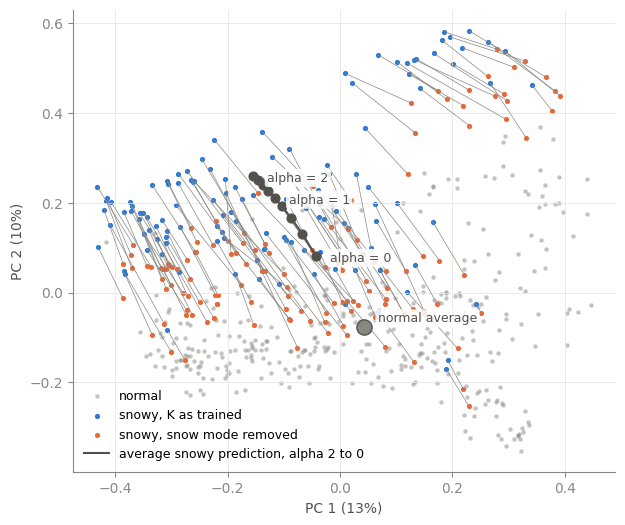

In [15]:
before, after = embed(predict(kae, x[:, 0])), embed(predict(removed, x[:, 0]))
moved = (after - before).norm(dim=-1)
print(f"Median movement: snowy {moved[is_snowy].median():.3f}, normal {moved[~is_snowy].median():.3f}")

snowy = is_snowy.numpy()
pca = PCA(2).fit(before.numpy())
before_2d, after_2d = pca.transform(before.numpy()), pca.transform(after.numpy())
path = np.stack([pca.transform(embed(predict(dampen(SNOW_MODE, alpha), snowy_x[:, 0])).mean(dim=0, keepdim=True).numpy())[0] for alpha in ALPHAS])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(*before_2d[~snowy].T, s=10, color=MUTED, alpha=0.5, lw=0, label="normal")
for i in snowy.nonzero()[0]:
    ax.plot([before_2d[i, 0], after_2d[i, 0]], [before_2d[i, 1], after_2d[i, 1]], color=MUTED, lw=0.5)
ax.scatter(*before_2d[snowy].T, s=14, color=BLUE, lw=0, label="snowy, K as trained")
ax.scatter(*after_2d[snowy].T, s=14, color=ORANGE, lw=0, label="snowy, snow mode removed")
ax.plot(*path.T, color=INK, lw=1.5, label="average snowy prediction, alpha 2 to 0")
ax.scatter(*path.T, s=40, color=INK, zorder=3)
for alpha, point in zip(ALPHAS, path):
    if alpha in (0.0, 1.0, 2.0):
        ax.annotate(
            f"alpha = {alpha:g}",
            point,
            xytext=(10, -4),
            textcoords="offset points",
            fontsize=9,
            color=INK,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
        )
ax.scatter(*before_2d[~snowy].mean(axis=0), s=120, color=MUTED, edgecolor=INK, zorder=3)
ax.annotate(
    "normal average",
    before_2d[~snowy].mean(axis=0),
    xytext=(10, 4),
    textcoords="offset points",
    fontsize=9,
    color=INK,
    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
)
ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(loc="lower left", fontsize=9)
plt.show()

##### Other confounders: where CLIP itself fails

Snow makes CLIP itself fail on vehicles. To look for other factors like it, we use CLIP's zero-shot errors on ImageNet's 1.28 million training images. CLIP never trained on ImageNet, so these errors are honest, and each class has about 1,300 images. The KAE is used only to say which modes are on.

NOTE: The only cache with patch statistics for the training set holds 3 augmented views (random crops of 60-100% of the image, and flips), stored view after view. We use the first view, so each image here is one random crop. CLIP's answer and the KAE's modes come from the same crop, so the comparison is consistent, but the galleries show the full image.

For each class and mode, we compare CLIP's accuracy on the class with the mode on against off. We keep snow-like candidates:
- the mode is on for at most 20% of all images, and spreads over at least 20 classes in its top 50;
- within the class, the mode is on for at least 50 images and at most 40% of them.

Pairs are ranked by a two-proportion z-score, keeping one pair per class.

In [16]:
train = torch.load(root / "imagenet" / "clip_cls_patch_std_ViT-B-32_train_3_views_blocks_5_11.pt", mmap=True)
count = len(train["labels"]) // 3
train_y = train["labels"][:count]
assert torch.equal(train_y, train["labels"][count : 2 * count]), "views are not stored one after another"
train_on, train_answers = [], []
for start in range(0, count, 20_000):
    batch = (train["states"][start : min(start + 20_000, count)].float() - mean) / std
    train_on.append(get_activity(batch[:, 0]) > 0)
    train_answers.append(classify(batch[:, 1]))
train_on, train_answers = torch.cat(train_on), torch.cat(train_answers)
train_wrong = train_answers != train_y
del train
print(f"CLIP zero-shot on one random crop of each ImageNet training image: {1 - train_wrong.double().mean():.3f}")

classes_in_top_50 = torch.tensor([len(set(val_y[activity[:, mode].topk(50).indices].tolist())) for mode in range(len(eigenvalues))])
eligible = (train_on.double().mean(dim=0) <= 0.2) & (classes_in_top_50 >= 20)

rows = []
for c in range(1_000):
    indices = (train_y == c).nonzero()[:, 0]
    on, wrong = train_on[indices], train_wrong[indices]
    n_on = on.sum(dim=0).double()
    n_off = len(indices) - n_on
    p_on = (on & wrong[:, None]).sum(dim=0) / n_on.clamp(min=1)
    p_off = (~on & wrong[:, None]).sum(dim=0) / n_off.clamp(min=1)
    pooled = (p_on * n_on + p_off * n_off) / len(indices)
    z = (p_on - p_off) / (pooled * (1 - pooled) * (1 / n_on.clamp(min=1) + 1 / n_off.clamp(min=1))).sqrt().clamp(min=1e-9)
    keep = eligible & (n_on >= 50) & (n_on <= 0.4 * len(indices))
    if not keep.any():
        continue

    mode = int(torch.where(keep, z, -torch.inf).argmax())
    mistakes = train_answers[indices[on[:, mode] & wrong]]
    rows.append(
        {
            "class": c,
            "mode": mode,
            "z": z[mode].item(),
            "images with mode on": int(n_on[mode]),
            "CLIP accuracy, mode on": 1 - p_on[mode].item(),
            "CLIP accuracy, mode off": 1 - p_off[mode].item(),
            "CLIP's usual wrong answer": class_names[int(torch.mode(mistakes).values)],
        }
    )

pairs = pd.DataFrame(rows).sort_values("z", ascending=False).reset_index(drop=True)
pairs.insert(0, "class name", pairs["class"].map(lambda c: class_names[c]))
pairs.head(12).round(3)

CLIP zero-shot on one random crop of each ImageNet training image: 0.635


,class name,class,mode,z,images with mode on,"CLIP accuracy, mode on","CLIP accuracy, mode off",CLIP's usual wrong answer
0,Pickelhaube,715,227,19.554,290,0.307,0.873,military uniform
1,baseball,429,494,14.110,224,0.339,0.803,baseball player
2,airplane wing,908,395,13.694,356,0.365,0.769,military aircraft
3,apiary,410,875,12.445,55,0.400,0.920,honeycomb
4,ski,795,398,11.792,52,0.327,0.891,scabbard
5,gymnastic horizontal bar,602,139,11.647,124,0.242,0.747,swing
6,rotisserie,766,196,11.449,434,0.491,0.800,microwave oven
7,wallet,893,242,10.897,494,0.277,0.588,pencil case
8,gar fish,395,516,10.652,287,0.279,0.633,silver salmon
9,bell or wind chime,494,824,10.441,281,0.139,0.485,gong


The three strongest pairs: each mode's top validation images, then training images of the class that CLIP gets wrong while the mode is on, labelled with CLIP's answer.

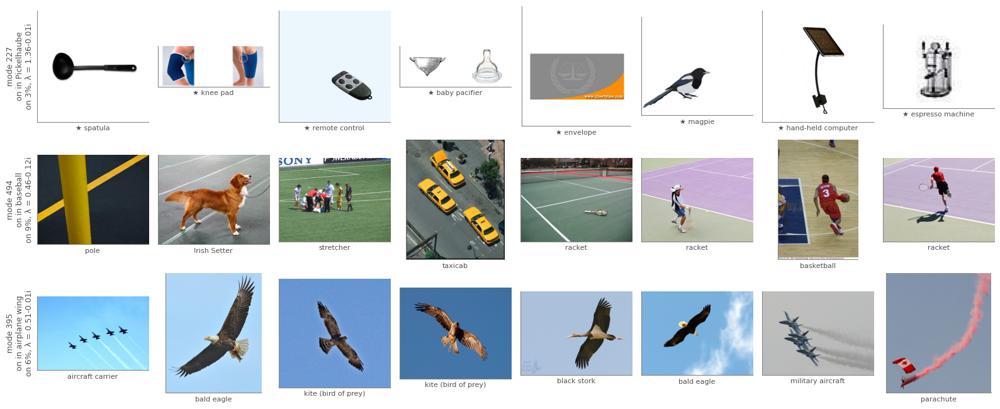

Loading dataset shards:   0%|          | 0/267 [00:00<?, ?it/s]

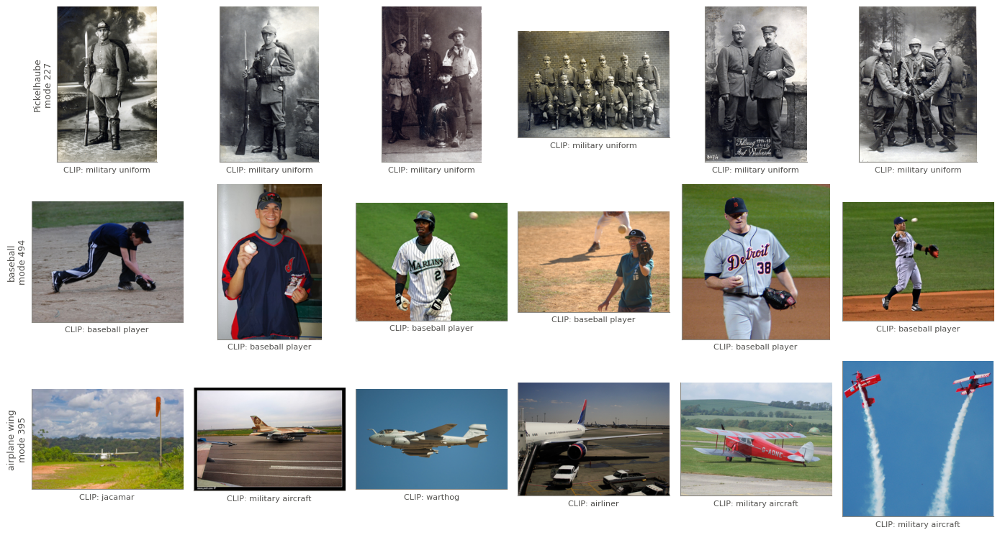

In [17]:
show_modes(list(pairs["mode"][:3]), [f"on in {name}" for name in pairs["class name"][:3]])

train_images = load_dataset("ILSVRC/imagenet-1k", split="train", cache_dir=os.getenv("DATASETS_CACHE"))
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for row, c, mode in zip(axes, pairs["class"][:3], pairs["mode"][:3]):
    indices = ((train_y == c) & train_on[:, mode] & train_wrong).nonzero()[:, 0][:6]
    for ax, index in zip(row, indices.tolist()):
        image = train_images[index]["image"].convert("RGB")
        image.thumbnail((256, 256))
        ax.imshow(np.asarray(image))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        ax.set_xlabel(f"CLIP: {class_names[train_answers[index]][:22]}", fontsize=8, color=INK)
    row[0].set_ylabel(f"{class_names[c]}\nmode {mode}", fontsize=9, color=INK)
fig.tight_layout()
plt.show()

Does removing the mode fix these errors in the KAE? For the top 20 pairs, on validation: fixes and breaks within the class, and everywhere else the mode is on.

In [18]:
rows = []
for c, mode in zip(pairs["class"][:20], pairs["mode"][:20]):
    on = activity[:, mode] > 0
    truth = val_y[on]
    before, after = classify(predict(kae, val_x[on, 0])), classify(predict(dampen(mode, 0.0), val_x[on, 0]))
    fixed, broken, target = (before != truth) & (after == truth), (before == truth) & (after != truth), truth == c
    rows.append(
        {
            "class": class_names[c],
            "mode": mode,
            "validation images": int(target.sum()),
            "class fixed": int((fixed & target).sum()),
            "class broken": int((broken & target).sum()),
            "elsewhere fixed": int((fixed & ~target).sum()),
            "elsewhere broken": int((broken & ~target).sum()),
        }
    )
removals = pd.DataFrame(rows)
print("Summed over the 20 pairs:", removals.drop(columns=["class", "mode"]).sum().to_dict())
removals

Summed over the 20 pairs: {'validation images': 254, 'class fixed': 2, 'class broken': 1, 'elsewhere fixed': 606, 'elsewhere broken': 823}


,class,mode,validation images,class fixed,class broken,elsewhere fixed,elsewhere broken
0,Pickelhaube,227,47,0,0,25,48
1,baseball,494,6,0,0,15,21
2,airplane wing,395,23,0,0,15,23
3,apiary,875,4,0,0,6,10
4,ski,398,0,0,0,3,1
5,gymnastic horizontal bar,139,4,0,0,114,117
6,rotisserie,196,8,0,0,21,32
7,wallet,242,15,1,0,24,48
8,gar fish,516,7,0,0,6,16
9,bell or wind chime,824,6,0,0,11,9
